# SFH posterior from S-PLUS colours (part 3)

Two SFH models, each with its own normalizing flow (trained by `train_ml_model.py --sfh-model <model>` on the 3090):
- **delayed-τ** (`delayed`): 9 targets, which are log age, log τ, log metallicity, the dust (`av_ism`, `log_tau_bc`), `logU`, the formed and the surviving mass, and the redshift;
- **double power law** (`dblplaw`): 10 targets, which are log turnover lookback time (the lookback time to τ, the turnover of the double power law), log α and log β, then the delayed-τ targets from log metallicity on.

Every other label (`mw_age`, `f_young`, `f_mid`, `f_old`, `log_sfr`, `log_ssfr`, ...) is derived from the samples with the same functions as the training labels (`ml_data.decode_samples`). Inputs are the 11 colours against r, the r magnitude (only for the absolute masses), and z_obs with its uncertainty (0 for spectroscopic redshifts).

Sections 1–4 run once per model in `SFH_MODELS`. Section 5 compares the two models and needs both.

**Bagpipes references.** Each model has its own photometric fits (columns `sm.PHOTOMETRIC_PREFIXES[model]`) and its own spectral fits (columns `sm.SPECTRAL_PREFIXES[model]`: plain names for delayed-τ, `spec_dblplaw_` for DPL) in `spectroscopic_reference.csv`. The split into `validation` and `test` halves is the delayed-τ spectral split, for both models.

**Inputs:** delayed-τ keeps the plain names; DPL adds `_dblplaw` (`sfh_models.model_file`).
- Per model: `ml_runs/mlp[_dblplaw]/`, `synthetic_validation[_dblplaw].parquet`, `synthetic_test[_dblplaw].parquet`, `training_set[_dblplaw].parquet` (prior draws).
- Shared: `spectroscopic_reference.csv`, `photometric_cross_fits.csv` (ln Z of the cross-fitted calibration mocks, notebook 2 section 6c; section 5.4), `dr3_corrected.csv`.

**Outputs:** `ml_evaluation_summary[_dblplaw].csv`, `ml_sfh_catalogue[_dblplaw].parquet`, `ml_model_comparison.csv`.

**Run:** top to bottom with the *Inference4ETGs (MultiNest)* kernel, on the PC, as a GPU notebook job with 16 cores and a 12 h limit (`GPU=1 CORES=16 MEMORY_MB=7100 TIME_LIMIT=12:00:00 HLJOB_OPTIONS=--pause-llm remote/submit_notebook.sh ml_model.ipynb <inputs>`, with the inputs listed above). Decoding a DPL sample sums Bagpipes' age grid (about 0.06 ms), so the decoding runs in `N_DECODE_JOBS` threads.

**Locked test.** Sections marked **LOCKED** run only with `RUN_LOCKED_TEST = True`, once, for both models, after the user has inspected the validation results. They use the synthetic test sets and the reference set's test half:
- the spectral comparisons (sections 3, 3b, 5.1, 5.3, 5.5) cover the test half whenever it is unlocked, since both models' spectral fits cover every galaxy with a spectrum;
- the photometric Bagpipes fits of the test half exist only when notebook 2 exported and read them (`EXPORT_LOCKED_TEST_JOBS = True`); without them the photometric and photometric-evidence comparisons cover the validation half, and the notebook says so.

Posterior samples for the same seed differ between CUDA and CPU (`DEVICE`): numbers are reproducible per device, not across devices. `ml_networks.load_run` refuses a checkpoint trained for another SFH model or other targets (e.g. the 16-bin runs): retrain it.

In [1]:
import gc
import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
import torch

import ml_data
import ml_evaluation as ev
import ml_networks
import sfh_models
import synthetic_model as sm

RUN_LOCKED_TEST = False            # set True once, for the final report (both models)
SFH_MODELS = ["delayed", "dblplaw"]   # evaluated in sections 1-4; section 5 needs both
EMBEDDING = "mlp"                  # the CNN lost in the 16-bin comparison, so only the MLP is trained
RUN_DIRECTORIES = {}
for sfh_model in SFH_MODELS:
    RUN_DIRECTORIES[sfh_model] = sfh_models.model_file(f"ml_runs/{EMBEDDING}", sfh_model)
# Per-model files: these names are the delayed-tau ones; sfh_models.model_file adds the other models' suffix
VALIDATION_FILE = "synthetic_validation.parquet"
TEST_FILE = "synthetic_test.parquet"
TRAINING_FILE = "training_set.parquet"
SUMMARY_FILE = "ml_evaluation_summary.csv"
CATALOGUE_FILE = "ml_sfh_catalogue.parquet"
# Shared files. REFERENCE_FILE holds each model's photometric Bagpipes fits under sm.PHOTOMETRIC_PREFIXES
REFERENCE_FILE = "spectroscopic_reference.csv"
# ln Z of every calibration mock under both models (notebook 2, section 6c)
CROSS_FITS_FILE = "photometric_cross_fits.csv"
SPLUS_FILE = "dr3_corrected.csv"
COMPARISON_FILE = "ml_model_comparison.csv"

N_POSTERIOR_SAMPLES = 1000         # per galaxy for evaluation
N_CATALOGUE_SAMPLES = 500          # per galaxy for the DR3 catalogue
SAMPLING_SEED = 7
VALIDATION_SEEDS = {"spectroscopic": 100, "photometric": 101}   # same copies as training used
TEST_SEEDS = {"spectroscopic": 200, "photometric": 201}
PRIOR_WINDOW_DZ = 0.05             # prior draws within this redshift of a galaxy define its prior width
MIN_PROB_GALAXY = 0.8
PASSIVE_SSFR_LIMIT = -11            # [log10 yr^-1] spectral sSFR below this = passive galaxy
PRIOR_SEED = 11                     # brightness offsets of the prior draws
N_JOBS = 11                         # processes of the DR3 coverage test
N_DECODE_JOBS = 15                  # threads decoding posterior samples: a DPL sample sums Bagpipes' age grid
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"   # flow sampling is autoregressive: slow on CPU


def evaluated_labels(sfh_model):
    """The label lists one SFH model is evaluated on.

    Returns: dict with
      flow_target_labels: its flow targets as decoded labels. decode_samples returns tau_bc but not
        log_tau_bc, so that target is evaluated as tau_bc;
      key_labels: those, then every derived label not among them (mw_age, f_young, f_mid, f_old, log_sfr,
        log_ssfr). The linear SFH parameters are left out: they are monotone maps of the log targets, so
        their ranks are the same and their coverage nearly so;
      judged_labels: the model's calibration labels, which the "works" test judges;
      reported_labels: the shared labels (sfh_models.SHARED_LABELS) not among them, reported but not judged;
      reference_labels: the judged labels, then the reported ones, compared with the Bagpipes posteriors.
    """
    flow_target_labels = []
    for name in ml_data.target_names(sfh_model):
        if name == "log_tau_bc":
            flow_target_labels.append("tau_bc")
        else:
            flow_target_labels.append(name)
    key_labels = [*flow_target_labels, "mw_age", "f_young", "f_mid", "f_old", "log_sfr", "log_ssfr"]
    judged_labels = list(sfh_models.MODELS[sfh_model].calibration_labels)
    reported_labels = []
    for label in sfh_models.SHARED_LABELS:
        if label not in judged_labels:
            reported_labels.append(label)
    return {"flow_target_labels": flow_target_labels, "key_labels": key_labels,
            "judged_labels": judged_labels, "reported_labels": reported_labels,
            "reference_labels": judged_labels + reported_labels}


LABELS = {}
runs = {}
for sfh_model in SFH_MODELS:
    LABELS[sfh_model] = evaluated_labels(sfh_model)
    wanted = set(LABELS[sfh_model]["key_labels"]) | set(LABELS[sfh_model]["reference_labels"])
    undecoded = wanted - set(sfh_models.MODELS[sfh_model].training_labels)
    if undecoded:                  # fail here, before any GPU sampling, not with a KeyError in the evaluation
        raise ValueError(f"{sfh_model}: labels the decoder does not return: {sorted(undecoded)}")
    runs[sfh_model] = ml_networks.load_run(RUN_DIRECTORIES[sfh_model], sfh_model, device=DEVICE)

BAGPIPES: Generating IGM absorption table.


Bagpipes: Latex turned off in rcParams, plots may look strange.


Bagpipes: PyMultiNest import failed, fitting will use the Nautilus sampler instead.


## 1. Training and validation

The MLP is the only embedding (the CNN lost in the 16-bin comparison). For each SFH model, this section shows the training history and the coverage of the key labels on the model's synthetic validation set. The two models' losses are not comparable: they model different targets.

delayed: 16221 galaxies x 1000 samples, sampled in 433 s on cuda, decoded in 6 s (2591541 samples/s, 15 threads)


delayed: 16221 galaxies x 1000 samples, sampled in 423 s on cuda, decoded in 5 s (3092412 samples/s, 15 threads)


dblplaw: 16230 galaxies x 1000 samples, sampled in 521 s on cuda, decoded in 388 s (41830 samples/s, 15 threads)


dblplaw: 16230 galaxies x 1000 samples, sampled in 524 s on cuda, decoded in 388 s (41856 samples/s, 15 threads)


,best_validation_loss,mean_coverage_error
sfh_model,,
dblplaw,-6.2186,0.0246
delayed,-7.7729,0.0483


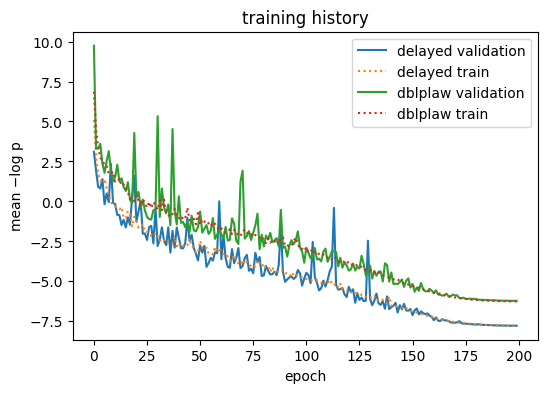

In [2]:
GALAXY_CHUNK = 500   # galaxies decoded at once: all labels of 16k x 1000 samples would need ~2.6 GB


def labelled_posteriors(run, observations, n_samples, seed, labels=None):
    """Decoded posterior labels for every valid galaxy: dict label -> array (n_valid, n_samples).

    run: (estimator, config, standardisers) from ml_networks.load_run. Its config names the SFH model the
    samples are decoded with. labels: names to keep, by default all of the model's training labels.
    Decoding runs in galaxy chunks, so only the kept labels are ever held for the whole set; each chunk is
    decoded in N_DECODE_JOBS threads (a DPL sample sums Bagpipes' age grid, about 0.06 ms).
    Returns: (posteriors, truths); truths are the decoded observations["targets"] of the valid galaxies.
    Prints the sampling and decoding time.
    """
    estimator, config, standardisers = run
    sfh_model = config["sfh_model"]
    valid = observations["valid"]
    if not valid.any():
        raise ValueError("no valid galaxy (every galaxy lacks a detected r band or a brightness donor): "
                         "nothing to predict")
    flat = observations["flat"][valid]
    banded = observations["banded"][valid]
    n_galaxies = len(flat)

    posteriors = {}
    sampling_seconds = 0.0
    decoding_seconds = 0.0
    for chunk_start in range(0, n_galaxies, GALAXY_CHUNK):
        chunk = slice(chunk_start, chunk_start + GALAXY_CHUNK)
        start = time.time()
        theta = ml_networks.posterior_samples(estimator, standardisers, flat[chunk], banded[chunk],
                                              n_samples, seed + chunk_start, DEVICE)
        sampling_seconds += time.time() - start
        n_chunk = theta.shape[0]
        start = time.time()
        decoded = ml_data.decode_samples(theta.reshape(-1, config["n_targets"]), sfh_model,
                                         n_jobs=N_DECODE_JOBS)
        decoding_seconds += time.time() - start
        for column in decoded.columns:
            if labels is not None and column not in labels:
                continue
            if column not in posteriors:
                posteriors[column] = np.empty((n_galaxies, n_samples))
            posteriors[column][chunk] = decoded[column].to_numpy().reshape(n_chunk, n_samples)
    truths = ml_data.decode_samples(observations["targets"][valid], sfh_model, n_jobs=N_DECODE_JOBS)
    n_decoded = n_galaxies * n_samples
    print(f"{sfh_model}: {n_galaxies} galaxies x {n_samples} samples, sampled in {sampling_seconds:.0f} s on "
          f"{DEVICE}, decoded in {decoding_seconds:.0f} s "
          f"({n_decoded / max(decoding_seconds, 1e-9):.0f} samples/s, "
          f"{N_DECODE_JOBS} threads)")
    return posteriors, truths


figure, axis = plt.subplots(figsize=(6, 4))
validation_tables = {}
choices = {}                       # sfh_model -> coverage of the key labels on the synthetic validation set
for sfh_model, run in runs.items():
    validation_tables[sfh_model] = pd.read_parquet(sfh_models.model_file(VALIDATION_FILE, sfh_model))
    history = pd.read_csv(os.path.join(RUN_DIRECTORIES[sfh_model], ml_networks.HISTORY_FILE))
    axis.plot(history["epoch"], history["validation_loss"], label=f"{sfh_model} validation")
    axis.plot(history["epoch"], history["train_loss"], ls=":", label=f"{sfh_model} train")
    choice_rows = []
    for mode, seed in VALIDATION_SEEDS.items():
        observations = ml_data.validation_observations(validation_tables[sfh_model], mode,
                                                       np.random.default_rng(seed), sfh_model)
        posteriors, truths = labelled_posteriors(run, observations, N_POSTERIOR_SAMPLES, SAMPLING_SEED,
                                                 LABELS[sfh_model]["key_labels"])
        for label in LABELS[sfh_model]["key_labels"]:
            coverage = ev.coverage_curve(posteriors[label], truths[label].to_numpy(), [0.68, 0.95])
            choice_rows.append({"sfh_model": sfh_model, "embedding": EMBEDDING, "mode": mode, "label": label,
                                "coverage_68": coverage[0], "coverage_95": coverage[1],
                                "best_validation_loss": history["validation_loss"].min()})
        del posteriors, truths   # one set of synthetic posteriors at a time (GPU jobs: ~7.1 GB)
        gc.collect()
    choice = pd.DataFrame(choice_rows)
    choice["coverage_error"] = np.abs(choice["coverage_68"] - 0.68) + np.abs(choice["coverage_95"] - 0.95)
    choices[sfh_model] = choice
axis.set(xlabel="epoch", ylabel="mean −log p", title="training history")
axis.legend()
by_model = pd.concat(choices.values(), ignore_index=True).groupby("sfh_model").agg(
    best_validation_loss=("best_validation_loss", "first"), mean_coverage_error=("coverage_error", "mean"))
display(by_model.round(4))
plt.show()

## 2. Calibration, accuracy and information per parameter (LOCKED: synthetic test set)

For each SFH model and redshift mode:
- the left panel is the coverage curve of the key labels (a calibrated posterior lies on the diagonal);
- the right panel is the histogram of the rank of the truth among the posterior samples (flat means calibrated, U-shaped means too narrow).

The table gives coverage, bias, NMAD and posterior/prior width for every key label (`LABELS[model]["key_labels"]`):
- the flow targets (9 for delayed-τ, 10 for DPL). `log_tau_bc` is evaluated as the decoded `tau_bc`, so its bias and NMAD are linear, not in dex like the log rows;
- the derived labels `mw_age` [Gyr], `f_young`, `f_mid`, `f_old`, `log_sfr` and `log_ssfr`.

The linear SFH parameters (`age`, `tau`, `turnover_lookback`, `alpha`, `beta`, `metallicity`) are not listed: they are monotone maps of the log targets, so their ranks are the same and their coverage nearly so.

Several derived labels have point masses in the prior:
- `f_young` and `f_old` are often exactly 0 or 1;
- `log_sfr` and `log_ssfr` sit on their floor when nothing formed in the last 100 Myr.

Ties make the inclusive coverage too high and pile the ranks at one edge, and a zero prior width gives a NaN width ratio. Read those rows as report-only.

In [3]:
def mass_rescaled_prior(prior_table, catalogue, seed):
    """Prior draws sorted by redshift, with the mass-like labels at observed brightness.

    Why: the training sets hold models at a fixed mass. An observed galaxy has the mass of its brightness
    (sm.scale_to_observed_r, as in training), so the prior width of log_mstar is ~1 dex, not 0.08.
    Inputs: prior_table: a model's training set; catalogue: DataFrame with r_auto and zml of DR3 galaxies;
            seed: for the brightness donors. Returns: DataFrame without rows lacking a donor, sorted by redshift.
    """
    offsets = sm.scale_to_observed_r(prior_table[sm.BANDS].to_numpy(dtype=float),
                                     prior_table["redshift"].to_numpy(dtype=float),
                                     catalogue["r_auto"].to_numpy(), catalogue["zml"].to_numpy(),
                                     np.random.default_rng(seed))[1]
    rescaled = sm.rescale_mass_labels(prior_table, offsets)
    return rescaled[np.isfinite(offsets)].sort_values("redshift").reset_index(drop=True)


def windowed_width_ratio(posterior, prior_table, label, true_redshift):
    """Posterior/prior width of a label, the prior taken within PRIOR_WINDOW_DZ of each galaxy's redshift."""
    prior_widths = ev.windowed_prior_widths(prior_table["redshift"].to_numpy(), prior_table[label].to_numpy(),
                                            true_redshift, PRIOR_WINDOW_DZ)
    return ev.width_ratio(posterior, None, prior_widths=prior_widths)


synthetic_test_summaries = {}      # sfh_model -> metrics on its synthetic test set (RUN_LOCKED_TEST only)
test_tables = {}
if RUN_LOCKED_TEST:
    dr3_brightness = pd.read_csv(SPLUS_FILE, usecols=["PROB_GAL", "r_auto", "zml"])
    dr3_brightness = dr3_brightness[dr3_brightness["PROB_GAL"] > MIN_PROB_GALAXY]
    for sfh_model in SFH_MODELS:
        test_tables[sfh_model] = pd.read_parquet(sfh_models.model_file(TEST_FILE, sfh_model))
        prior_table = mass_rescaled_prior(pd.read_parquet(sfh_models.model_file(TRAINING_FILE, sfh_model)),
                                          dr3_brightness, PRIOR_SEED)
        key_labels = LABELS[sfh_model]["key_labels"]
        summary_rows = []
        for mode, seed in TEST_SEEDS.items():
            observations = ml_data.validation_observations(test_tables[sfh_model], mode,
                                                           np.random.default_rng(seed), sfh_model)
            posteriors, truths = labelled_posteriors(runs[sfh_model], observations, N_POSTERIOR_SAMPLES,
                                                     SAMPLING_SEED, key_labels)
            figure, axes = plt.subplots(1, 2, figsize=(12, 5))
            for label in key_labels:
                truth = truths[label].to_numpy()
                coverage = ev.coverage_curve(posteriors[label], truth)
                bias, nmad = ev.bias_and_nmad(np.nanmedian(posteriors[label], axis=1), truth)
                ratio = windowed_width_ratio(posteriors[label], prior_table, label,
                                             truths["redshift"].to_numpy())
                summary_rows.append({"sfh_model": sfh_model, "section": "synthetic_test", "mode": mode,
                                     "label": label,
                                     "coverage_68": ev.coverage_curve(posteriors[label], truth, [0.68])[0],
                                     "coverage_95": ev.coverage_curve(posteriors[label], truth, [0.95])[0],
                                     "bias": bias, "nmad": nmad, "width_ratio": ratio})
                axes[0].plot(ev.NOMINAL_LEVELS, coverage, marker="o", label=label)
                axes[1].hist(ev.truth_ranks(posteriors[label], truth), bins=20, histtype="step", label=label)
            axes[0].plot([0, 1], [0, 1], color="black", lw=1)
            axes[0].set(xlabel="nominal coverage", ylabel="empirical coverage",
                        title=f"{sfh_model}, {mode} redshift")
            axes[1].set(xlabel="rank of truth", ylabel="galaxies")
            axes[0].legend(fontsize=6, ncol=2)
            plt.show()
            del posteriors, truths   # one set of synthetic posteriors at a time (GPU jobs: ~7.1 GB)
            gc.collect()
        synthetic_test_summaries[sfh_model] = pd.DataFrame(summary_rows)
        display(synthetic_test_summaries[sfh_model].round(3))
else:
    print("synthetic test evaluation: skipped (locked)")

synthetic test evaluation: skipped (locked)


In [4]:
if RUN_LOCKED_TEST:
    BAR_WIDTH = 0.4
    for sfh_model in SFH_MODELS:
        # Information per parameter: posterior width / prior width of each flow target
        # (1 = the colours say nothing about that parameter)
        summary = synthetic_test_summaries[sfh_model]
        flow_target_labels = LABELS[sfh_model]["flow_target_labels"]
        figure, axis = plt.subplots(figsize=(9, 4))
        for mode_index, mode in enumerate(TEST_SEEDS):
            mode_rows = summary[(summary["mode"] == mode) & summary["label"].isin(flow_target_labels)]
            width_ratios = mode_rows.set_index("label").loc[flow_target_labels, "width_ratio"]
            axis.bar(np.arange(len(flow_target_labels)) + (mode_index - 0.5) * BAR_WIDTH, width_ratios,
                     width=BAR_WIDTH, label=f"{mode} redshift")
        axis.axhline(1, color="grey", ls=":")
        axis.set_xticks(range(len(flow_target_labels)))
        axis.set_xticklabels(flow_target_labels, rotation=45, ha="right")
        axis.set(ylabel="posterior / prior 68% width",
                 title=f"{sfh_model}: information per parameter (1 = prior only)")
        axis.legend()
        plt.show()

        # Accuracy against brightness, spectroscopic mode
        spectroscopic_rng = np.random.default_rng(TEST_SEEDS["spectroscopic"])
        observations = ml_data.validation_observations(test_tables[sfh_model], "spectroscopic",
                                                       spectroscopic_rng, sfh_model)
        posteriors, truths = labelled_posteriors(runs[sfh_model], observations, N_POSTERIOR_SAMPLES,
                                                 SAMPLING_SEED, ["mw_age", "log_mstar"])
        r_magnitude = observations["flat"][observations["valid"], ml_data.SCALAR_INPUT_SLICE.start]
        r_quartile = pd.qcut(r_magnitude, 4, labels=["brightest", "second", "third", "faintest"])
        accuracy_rows = []
        for label in ("mw_age", "log_mstar"):
            medians = np.nanmedian(posteriors[label], axis=1)
            for quartile in r_quartile.categories:
                in_quartile = np.asarray(r_quartile == quartile)
                bias, nmad = ev.bias_and_nmad(medians[in_quartile], truths[label].to_numpy()[in_quartile])
                accuracy_rows.append({"sfh_model": sfh_model, "label": label, "r_quartile": quartile,
                                      "bias": bias, "nmad": nmad})
        display(pd.DataFrame(accuracy_rows).round(3))
        del posteriors, truths   # one set of synthetic posteriors at a time (GPU jobs: ~7.1 GB)
        gc.collect()
else:
    print("information per parameter and accuracy against brightness: skipped (locked)")

information per parameter and accuracy against brightness: skipped (locked)


## 3. Agreement with the Bagpipes spectral posteriors

For each SFH model: ML posteriors from the 3″ aperture colours and spectroscopic redshift, against each reference galaxy's spectral posterior. There are two spectral references, one per SFH model (`sm.SPECTRAL_PREFIXES`):
- the **delayed-τ spectral fits** (plain column names) hold the shared labels and the delayed-τ parameters;
- the **DPL spectral fits** (`spec_dblplaw_<label>`) hold the shared labels and the DPL parameters.

Every ML model is compared with both references, on the labels each reference holds. A galaxy enters a reference's comparison when its spectral fit of that model converged. The galaxy type (passive or star-forming) comes from the delayed-τ spectral sSFR for both references, so a galaxy has the same type in every table. Development uses the `validation` half; the `test` half is LOCKED.

In [ ]:
reference = pd.read_csv(REFERENCE_FILE, dtype={"specobjid": str})
halves = ["validation", "test"] if RUN_LOCKED_TEST else ["validation"]
SPECTRAL_REFERENCES = list(sm.SPECTRAL_PREFIXES)   # one spectral Bagpipes reference per SFH model
aperture_columns = []
aperture_error_columns = []
for band in sm.BANDS:
    aperture_columns.append(f"{band}_aper")
    aperture_error_columns.append(f"e_{band}_aper")


def available_labels(table, labels, prefix=""):
    """The labels whose {prefix}<label>_median column the table holds (a reference set may lack some)."""
    kept = []
    for label in labels:
        if f"{prefix}{label}_median" in table.columns:
            kept.append(label)
    return kept


def spectral_galaxy_types(galaxies):
    """'star-forming' where the delayed-tau spectral fit's log_ssfr_median exceeds PASSIVE_SSFR_LIMIT.

    The other galaxies are 'passive'. Both spectral references use this one split, so a galaxy has the same
    type in every comparison.
    Returns: array of str, one per galaxy.
    """
    is_star_forming = galaxies["log_ssfr_median"].to_numpy(dtype=float) > PASSIVE_SSFR_LIMIT
    return np.where(is_star_forming, "star-forming", "passive")


def converged_fits(galaxies, prefix):
    """True where the galaxy's Bagpipes fit with this column prefix exists and converged (array).

    prefix: a photometric prefix (sm.PHOTOMETRIC_PREFIXES) or a spectral one (sm.SPECTRAL_PREFIXES; "" reads
    the delayed-tau spectral column "converged"). A table without the {prefix}converged column (e.g. before
    the DPL fits are read) gives False everywhere.
    """
    column = f"{prefix}converged"
    if column not in galaxies.columns:
        return np.zeros(len(galaxies), dtype=bool)
    return galaxies[column].astype("boolean").fillna(False).to_numpy(dtype=bool)


def spectral_fits(galaxies, spectral_model):
    """True where the galaxy has a converged spectral fit of this SFH model (array).

    The galaxy needs its delayed-tau spectral fit (fit_status "fitted"), which defines the split, and the
    converged flag of the model's own spectral fit. Every galaxy of a half has a converged delayed-tau fit
    (notebook 2 splits only those), so for delayed-tau this is every galaxy of the half.
    """
    has_delayed_fit = (galaxies["fit_status"] == "fitted").to_numpy()
    return has_delayed_fit & converged_fits(galaxies, sm.SPECTRAL_PREFIXES[spectral_model])


# Why one sampling pass per model and half: the spectral, photometric and cross-model comparisons must use
# the same ML draws of each galaxy, so each model's posterior is drawn once for every galaxy with a
# spectral fit or a photometric fit of that model
has_spectral_fit = reference["fit_status"] == "fitted"
# (sfh_model, half) -> (galaxies with an ML posterior, dict label -> (n, samples))
ml_posteriors_by_half = {}
# (ML model, spectral model) -> the ML of one model against the spectral fits of one model, one row per
# (half, galaxy, label)
agreements = {}
for sfh_model in SFH_MODELS:
    prefix = sm.PHOTOMETRIC_PREFIXES[sfh_model]
    has_photometric_fit = pd.Series(False, index=reference.index)
    if f"{prefix}mw_age_median" in reference.columns:
        has_photometric_fit = reference[f"{prefix}mw_age_median"].notna()
    n_targets = runs[sfh_model][1]["n_targets"]
    agreement_rows = {}
    for spectral_model in SPECTRAL_REFERENCES:
        agreement_rows[spectral_model] = []
    for half in halves:
        galaxies = reference[(reference["split"] == half) & (has_spectral_fit | has_photometric_fit)]
        galaxies = galaxies.reset_index(drop=True)
        if len(galaxies) == 0:
            print(f"{sfh_model}, {half}: no fitted galaxies yet")
            continue
        observations = ml_data.colour_inputs(galaxies[aperture_columns].to_numpy(),
                                             galaxies[aperture_error_columns].to_numpy(),
                                             galaxies["z"].to_numpy(), np.zeros(len(galaxies)))
        if not observations["valid"].any():
            print(f"{sfh_model}, {half}: no galaxy with a detected r band in the aperture photometry")
            continue
        observations["targets"] = np.zeros((len(galaxies), n_targets))   # unknown; not used
        posteriors, _ = labelled_posteriors(runs[sfh_model], observations, N_POSTERIOR_SAMPLES, SAMPLING_SEED)
        kept = galaxies[observations["valid"]].reset_index(drop=True)
        ml_posteriors_by_half[(sfh_model, half)] = (kept, posteriors)

        # The spectral comparisons: for each spectral reference, the galaxies whose fit of that model
        # converged, on the labels that reference holds
        for spectral_model in SPECTRAL_REFERENCES:
            spectral_prefix = sm.SPECTRAL_PREFIXES[spectral_model]
            spectral_labels = available_labels(reference, LABELS[sfh_model]["reference_labels"],
                                               spectral_prefix)
            spectral = spectral_fits(kept, spectral_model)
            if not spectral.any() or not spectral_labels:
                continue
            spectral_galaxies = kept[spectral].reset_index(drop=True)
            spectral_posteriors = {label: posteriors[label][spectral] for label in spectral_labels}
            galaxy_types = dict(zip(spectral_galaxies["specobjid"], spectral_galaxy_types(spectral_galaxies)))
            galaxy_details = spectral_galaxies.set_index("specobjid")
            fitter_column = f"{spectral_prefix}fitter_calibrated"
            for row in ev.reference_comparison_rows(spectral_posteriors, spectral_galaxies, spectral_labels,
                                                    prefix=spectral_prefix):
                details = galaxy_details.loc[row["specobjid"]]
                agreement_rows[spectral_model].append({
                    "sfh_model": sfh_model, "spectral_model": spectral_model, "half": half, **row,
                    "galaxy_type": galaxy_types[row["specobjid"]], "fibre": details["fiber_diameter"],
                    "calibrated_fitter": details.get(fitter_column, np.nan)})
    for spectral_model in SPECTRAL_REFERENCES:
        agreement = pd.DataFrame(agreement_rows[spectral_model])
        agreements[(sfh_model, spectral_model)] = agreement
        if len(agreement) == 0:
            print(f"{sfh_model} ML: no converged {spectral_model} spectral fits to compare with in "
                  f"{REFERENCE_FILE} yet")
            continue
        print(f"{sfh_model} ML against the {spectral_model} spectral Bagpipes posteriors")
        display(agreement.groupby(["half", "label"]).agg(median_offset=("offset_in_widths", "median"),
                                                          inside_68=("inside_68", "mean"),
                                                          inside_95=("inside_95", "mean"),
                                                          galaxies=("specobjid", "count")).round(3))
        display(agreement.groupby(["half", "label", "galaxy_type"])["inside_95"].mean().unstack().round(3))

### 3b. The "works" test: the model's own photometric and spectral Bagpipes

For each SFH model, the ML is compared with two Bagpipes references of the same model, and each answers a different question:

- **Photometric Bagpipes (emulator check).** These are the model's own photometric fits (notebook 2, section 6b for delayed-τ and 6c for DPL): `phot_<label>` for delayed-τ, `phot_dblplaw_<label>` for DPL (`sm.PHOTOMETRIC_PREFIXES`). They fit the same 3″ photometry the ML sees, under that model's training prior and the simulator's likelihood, so a faithful emulator must agree with them.
- **Spectral Bagpipes (physical check).** These are the model's own spectral fits to the SDSS spectra: plain `<label>` columns for delayed-τ, `spec_dblplaw_<label>` for DPL (`sm.SPECTRAL_PREFIXES`). Agreement tells whether the colours recover what the spectra say under the same SFH model. Section 5.3 compares every estimator with both spectral references on the shared labels.

A label agrees with a reference set when two conditions hold:
- at least `ev.MIN_INSIDE_95` (80%) of the reference medians lie inside the ML 95% interval;
- the median offset is within ±`ev.MAX_ABS_MEDIAN_OFFSET` combined 1σ widths.

The judged labels are the model's calibration labels. For delayed-τ they are `log_age`, `log_tau`, `log_metallicity` and `log_mstar`. For DPL they are `log_turnover_lookback`, `log_alpha`, `log_beta`, `log_metallicity` and `log_mstar`. Both of a model's references hold all of them. A judged label a reference set lacks (e.g. before notebook 2 has read the DPL spectral fits) is listed with the status "not in the reference" and stays out of the `all` row; without any judged label holding galaxies, the `all` row gives no verdict (empty).

The other shared labels (`sfh_models.SHARED_LABELS`) are reported, not judged. A reported label a reference set does not hold has an empty row. The `validation` half is always judged. With `RUN_LOCKED_TEST`, the `test` half is judged too (LOCKED): against the spectral fits always, against the photometric fits only when notebook 2 has read the test-half photometric fits. The verdicts are printed side by side, and the notebook draws no conclusion beyond them.

From Amendment 2 on, `agreement_spectral` in `ml_evaluation_summary_dblplaw.csv` is the DPL ML against the DPL spectral fits; the DPL ML against the delayed-τ spectra is in `ml_model_comparison.csv`, section `against_spectra`, `spectral_model` = `delayed`.

In [ ]:
REFERENCE_SET_NAMES = {"photometric": "its own photometric Bagpipes (emulator check)",
                       "spectral": "its own spectral Bagpipes (physical check)"}


NOT_IN_REFERENCE = "not in the reference"   # status of a judged label the reference set does not hold
# What gives a reference set fits in the test half (section 3b judges the test half only with RUN_LOCKED_TEST)
TEST_HALF_HINTS = {
    "photometric": "set EXPORT_LOCKED_TEST_JOBS = True in notebook 2, fit those jobs and read them",
    "spectral": "run notebook 2 after the spectral fits of the test half"}


def verdict_table(rows, judged_labels, reported_labels, not_in_reference=()):
    """One verdict table with a status column.

    Rows: agreement_verdict over the judged labels (status "judged", with its 'all' row, which covers only
    them); then the reported labels (status "reported", without their 'all' row); then the labels the
    reference set cannot judge (status NOT_IN_REFERENCE, no galaxies, agrees left empty).
    Why the empty 'all' row: when no judged label holds a galaxy (no judged label in the reference, or no
    fit read yet), agreement_verdict's 'all' row is no verdict, so its agrees is None rather than True or
    False.
    """
    judged = ev.agreement_verdict(rows, judged_labels).assign(status="judged")
    judged_label_rows = judged[judged["label"] != ev.ALL_LABELS_ROW]
    if judged_label_rows["n_galaxies"].sum() == 0:
        judged["agrees"] = judged["agrees"].astype(object)
        judged.loc[judged["label"] == ev.ALL_LABELS_ROW, "agrees"] = None
    tables = [judged, ev.agreement_verdict(rows, reported_labels).iloc[:-1].assign(status="reported")]
    if not_in_reference:
        missing_rows = []
        for label in not_in_reference:
            missing_rows.append({"label": label, "n_galaxies": 0, "inside_95": np.nan,
                                 "median_offset": np.nan, "agrees": None, "status": NOT_IN_REFERENCE})
        tables.append(pd.DataFrame(missing_rows))
    return pd.concat(tables, ignore_index=True)


def photometric_comparison_rows(sfh_model, half, labels):
    """The ML of one model against its own photometric Bagpipes fits in one half, with the draws of cell 8.

    Returns: (rows, n_fits, n_not_converged): reference_comparison_rows over the galaxies whose photometric
    fit converged; the galaxies with a fit and an ML posterior; those of them whose fit did not converge
    (left out).
    """
    prefix = sm.PHOTOMETRIC_PREFIXES[sfh_model]
    if (sfh_model, half) not in ml_posteriors_by_half or f"{prefix}mw_age_median" not in reference.columns:
        return [], 0, 0
    half_galaxies, half_posteriors = ml_posteriors_by_half[(sfh_model, half)]
    photometric = half_galaxies[f"{prefix}mw_age_median"].notna().to_numpy()
    n_fits = int(photometric.sum())
    if n_fits == 0:
        return [], 0, 0
    converged = converged_fits(half_galaxies, prefix)
    n_not_converged = int((photometric & ~converged).sum())
    compared = photometric & converged
    photometric_galaxies = half_galaxies[compared].reset_index(drop=True)
    photometric_posteriors = {label: half_posteriors[label][compared] for label in labels}
    rows = ev.reference_comparison_rows(photometric_posteriors, photometric_galaxies, labels, prefix=prefix)
    return rows, n_fits, n_not_converged


def fitter_calibration_flag(column):
    """The fitter_calibrated flag a reference set's column holds, or a note when it is empty or missing."""
    if column in reference.columns:
        flags = reference[column].dropna()
        if len(flags) > 0:
            return flags.iloc[0]
    return "unknown (calibration mocks not all fitted, or fits not read)"


verdicts = {}                      # (sfh_model, reference set, half) -> verdict table
for sfh_model in SFH_MODELS:
    prefixes = {"photometric": sm.PHOTOMETRIC_PREFIXES[sfh_model],
                "spectral": sm.SPECTRAL_PREFIXES[sfh_model]}
    judged_labels = LABELS[sfh_model]["judged_labels"]
    reported_labels = LABELS[sfh_model]["reported_labels"]
    reference_labels = LABELS[sfh_model]["reference_labels"]
    labels_by_set = {}
    for reference_set, prefix in prefixes.items():
        labels_by_set[reference_set] = available_labels(reference, reference_labels, prefix)
        missing_labels = [label for label in reference_labels if label not in labels_by_set[reference_set]]
        if missing_labels:
            print(f"{sfh_model}: {REFERENCE_FILE} has no {reference_set} {prefix}<label> columns for "
                  f"{missing_labels}: their rows stay empty")
    # The judged labels each reference set holds. The photometric set judges the full list: a missing
    # column there means the fits are not read yet, so its labels stay judged and empty
    judged_by_set = {"photometric": judged_labels,
                     "spectral": available_labels(reference, judged_labels, prefixes["spectral"])}

    for half in halves:
        n_half = int((reference["split"] == half).sum())

        # 1. The galaxies of this half with a converged photometric fit of this model
        photometric_rows, n_photometric_fits, n_not_converged = photometric_comparison_rows(
            sfh_model, half, labels_by_set["photometric"])
        n_photometric_compared = len({row["specobjid"] for row in photometric_rows})
        print(f"{sfh_model}, {half} half: photometric fits of {n_photometric_compared} of {n_half} galaxies "
              f"compared ({n_photometric_fits} with a fit and an ML posterior, {n_not_converged} not "
              "converged and left out)")

        # 2. The galaxies of this half with a converged spectral fit of this model (cell 8)
        spectral_rows = agreements[(sfh_model, sfh_model)]
        if len(spectral_rows) > 0:
            spectral_rows = spectral_rows[spectral_rows["half"] == half]
        n_spectral_compared = 0
        if len(spectral_rows) > 0:
            n_spectral_compared = spectral_rows["specobjid"].nunique()
        print(f"{sfh_model}, {half} half: spectral fits of {n_spectral_compared} of {n_half} galaxies "
              "compared")
        comparison_rows = {"photometric": photometric_rows, "spectral": spectral_rows}

        # 3. Both verdicts side by side. Why the fitter flag: a reference whose fitter failed its calibration
        # test (or whose calibration mocks are not all fitted) is a weaker reference, so it is shown next to
        # the verdict
        for reference_set, rows in comparison_rows.items():
            if len(rows) == 0 and half != "validation":
                # The test half has photometric fits only with EXPORT_LOCKED_TEST_JOBS in notebook 2
                print(f"  {half} half: no {sfh_model} {reference_set} Bagpipes fits to compare with, so no "
                      f"verdict ({TEST_HALF_HINTS[reference_set]})")
                continue
            if len(rows) == 0:
                print(f"  no {sfh_model} {reference_set} Bagpipes fits in {REFERENCE_FILE} yet: "
                      "run notebook 2 after the fits")
            set_judged_labels = judged_by_set[reference_set]
            not_in_reference = [label for label in judged_labels if label not in set_judged_labels]
            verdict = verdict_table(rows, set_judged_labels, reported_labels, not_in_reference)
            verdicts[(sfh_model, reference_set, half)] = verdict
            fitter_calibrated = fitter_calibration_flag(f"{prefixes[reference_set]}fitter_calibrated")
            print(f"{sfh_model}: agreement with {REFERENCE_SET_NAMES[reference_set]} ({half} half; "
                  f"{', '.join(reported_labels)} reported, not judged); "
                  f"fitter calibrated: {fitter_calibrated}")
            display(verdict.round(3))
            if not_in_reference:
                print(f"  {', '.join(not_in_reference)}: {NOT_IN_REFERENCE}, so not judged here")
            judged_rows = verdict[verdict["status"] == "judged"]
            if judged_rows["n_galaxies"].sum() == 0:
                print(f"  no galaxy for the judged labels {set_judged_labels} in this reference set")
            else:
                all_row = verdict[verdict["label"] == ev.ALL_LABELS_ROW]
                print(f"  the ML agrees on {', '.join(set_judged_labels)}: {bool(all_row['agrees'].iloc[0])}")

## 4. S-PLUS DR3 catalogues

One catalogue per SFH model (`ml_sfh_catalogue.parquet`, `ml_sfh_catalogue_dblplaw.parquet`). Each holds photometric-z posteriors for every DR3 galaxy that passes that model's coverage test (against its own training set); the others are flagged.

In [7]:
splus = pd.read_csv(SPLUS_FILE)
splus = splus[splus["PROB_GAL"] > MIN_PROB_GALAXY].reset_index(drop=True)
magnitudes = splus[[f"{band}_auto" for band in sm.BANDS]].to_numpy()
errors = splus[[f"e_{band}_auto" for band in sm.BANDS]].to_numpy()
detected = sm.detected_bands(magnitudes, errors)
zml = splus["zml"].to_numpy()
sigma_z = sm.SIGMA_Z * (1 + zml)
inputs = ml_data.colour_inputs(magnitudes, errors, zml, sigma_z)
blocks = np.array_split(np.arange(len(splus)), 4 * N_JOBS)
CATALOGUE_CHUNK = 2000             # galaxies per chunk: all samples at once would need ~4 GB
SUMMARY_PERCENTILES = ((16, "p16"), (50, "median"), (84, "p84"))

catalogues = {}                    # sfh_model -> DR3 catalogue (also written to its parquet file)
for sfh_model in SFH_MODELS:
    # 1. Coverage test against this model's training set (colour-based through its free offset), in parallel
    training_models = pd.read_parquet(sfh_models.model_file(TRAINING_FILE, sfh_model),
                                      columns=["redshift", *sm.BANDS])
    tasks = []
    for block in blocks:
        tasks.append(delayed(sm.coverage_test)(magnitudes[block], errors[block], detected[block], zml[block],
                                               sm.redshift_window(zml[block]),
                                               training_models[sm.BANDS].to_numpy(),
                                               training_models["redshift"].to_numpy()))
    coverage = pd.concat(Parallel(n_jobs=N_JOBS)(tasks), ignore_index=True)

    # 2. Posterior summaries (16th, 50th, 84th percentile of every decoded label) for covered galaxies with a
    # detected r band
    predictable = inputs["valid"] & coverage["covered"].to_numpy()
    estimator, config, standardisers = runs[sfh_model]
    predictable_indices = np.flatnonzero(predictable)
    summaries = {}                 # column name -> values for every DR3 galaxy
    start = time.time()
    decoding_seconds = 0.0
    for chunk_start in range(0, len(predictable_indices), CATALOGUE_CHUNK):
        chunk = predictable_indices[chunk_start:chunk_start + CATALOGUE_CHUNK]
        theta = ml_networks.posterior_samples(estimator, standardisers, inputs["flat"][chunk],
                                              inputs["banded"][chunk], N_CATALOGUE_SAMPLES,
                                              SAMPLING_SEED + chunk_start, DEVICE)
        decoding_start = time.time()
        decoded = ml_data.decode_samples(theta.reshape(-1, config["n_targets"]), sfh_model,
                                         n_jobs=N_DECODE_JOBS)
        decoding_seconds += time.time() - decoding_start
        for column in decoded.columns:
            values = decoded[column].to_numpy().reshape(len(chunk), N_CATALOGUE_SAMPLES)
            for percentile, suffix in SUMMARY_PERCENTILES:
                name = f"{column}_{suffix}"
                if name not in summaries:
                    summaries[name] = np.full(len(splus), np.nan)
                summaries[name][chunk] = np.nanpercentile(values, percentile, axis=1)
    seconds = time.time() - start

    catalogue = splus[["RA", "DEC", "zml"]].copy()
    catalogue["no_r_band"] = ~inputs["valid"]
    catalogue["out_of_domain"] = inputs["valid"] & ~coverage["covered"].to_numpy()
    # Why one concat: adding ~60 columns one by one fragments the frame (a pandas PerformanceWarning)
    catalogue = pd.concat([catalogue, pd.DataFrame(summaries, index=catalogue.index)], axis=1)
    catalogue_file = sfh_models.model_file(CATALOGUE_FILE, sfh_model)
    catalogue.to_parquet(catalogue_file, index=False)
    catalogues[sfh_model] = catalogue
    n_predicted = len(predictable_indices)
    print(f"{sfh_model}: {n_predicted} of {len(splus)} galaxies predicted "
          f"({catalogue['out_of_domain'].mean():.1%} out of domain, "
          f"{catalogue['no_r_band'].sum()} without r); "
          f"{n_predicted / seconds:.0f} galaxies/s on {DEVICE}; wrote {catalogue_file}")
    n_decoded = n_predicted * N_CATALOGUE_SAMPLES
    print(f"  decoding took {decoding_seconds / 60:.1f} of {seconds / 60:.1f} min "
          f"({n_decoded / max(decoding_seconds, 1e-9):.0f} samples/s, {N_DECODE_JOBS} threads)")

Bagpipes: Latex turned off in rcParams, plots may look strange.
Bagpipes: PyMultiNest import failed, fitting will use the Nautilus sampler instead.


Bagpipes: Latex turned off in rcParams, plots may look strange.
Bagpipes: PyMultiNest import failed, fitting will use the Nautilus sampler instead.


Bagpipes: Latex turned off in rcParams, plots may look strange.
Bagpipes: PyMultiNest import failed, fitting will use the Nautilus sampler instead.


Bagpipes: Latex turned off in rcParams, plots may look strange.
Bagpipes: PyMultiNest import failed, fitting will use the Nautilus sampler instead.


Bagpipes: Latex turned off in rcParams, plots may look strange.
Bagpipes: PyMultiNest import failed, fitting will use the Nautilus sampler instead.


Bagpipes: Latex turned off in rcParams, plots may look strange.
Bagpipes: PyMultiNest import failed, fitting will use the Nautilus sampler instead.


... (11 outputs left out)

Bagpipes: Latex turned off in rcParams, plots may look strange.
Bagpipes: PyMultiNest import failed, fitting will use the Nautilus sampler instead.
Bagpipes: Latex turned off in rcParams, plots may look strange.
Bagpipes: PyMultiNest import failed, fitting will use the Nautilus sampler instead.


Bagpipes: Latex turned off in rcParams, plots may look strange.
Bagpipes: PyMultiNest import failed, fitting will use the Nautilus sampler instead.
Bagpipes: Latex turned off in rcParams, plots may look strange.
Bagpipes: PyMultiNest import failed, fitting will use the Nautilus sampler instead.


Bagpipes: Latex turned off in rcParams, plots may look strange.
Bagpipes: PyMultiNest import failed, fitting will use the Nautilus sampler instead.


dblplaw: 48632 of 54150 galaxies predicted (10.1% out of domain, 23 without r); 34 galaxies/s on cuda; wrote ml_sfh_catalogue_dblplaw.parquet
  decoding took 9.6 of 24.1 min (42205 samples/s, 15 threads)


In [ ]:
for sfh_model in SFH_MODELS:
    summary_tables = []
    if RUN_LOCKED_TEST:
        summary_tables.append(synthetic_test_summaries[sfh_model])
    summary_tables.append(choices[sfh_model].assign(section="validation_choice"))
    # The works-test verdicts of section 3b, in their order there: per half, photometric then spectral
    for (verdict_model, reference_set, half), verdict in verdicts.items():
        if verdict_model != sfh_model:
            continue
        summary_tables.append(verdict.assign(section=f"agreement_{reference_set}", half=half,
                                             sfh_model=sfh_model))
    summary_file = sfh_models.model_file(SUMMARY_FILE, sfh_model)
    pd.concat(summary_tables, ignore_index=True).to_csv(summary_file, index=False)
    print(f"wrote {summary_file}")

## 5. Delayed-τ against double power law

The two SFH models side by side, in five parts (spec 2026-10-28, Part 4 and Amendment 2):
1. each model's ML against its own photometric and its own spectral Bagpipes (the "works" tests of section 3b, side by side);
2. delayed-τ against DPL on the shared labels:
   - the ML of each model, on the validation galaxies and on DR3;
   - the photometric Bagpipes fits of each model, on the validation galaxies;
   - the spectral Bagpipes fits of each model, on the validation galaxies;
3. four estimators against both spectral references (delayed-τ and DPL spectral Bagpipes), passive and star-forming galaxies apart;
4. the photometric Bayesian evidence of each model, galaxy by galaxy and on the cross-fitted mocks;
5. the spectral Bayesian evidence of each model, galaxy by galaxy, and how it relates to the photometric one.

The shared labels are model-independent: `log_mstar`, `mw_age`, `log_metallicity`, `av_ism`, `log_ssfr`, `f_young`, `f_mid`, `f_old` (`sfh_models.SHARED_LABELS`).

Every difference is delayed-τ minus DPL. Only the validation half is used, plus the test half with `RUN_LOCKED_TEST` (LOCKED):
- the spectral comparisons (5.1 spectral, 5.2 spectral pair, 5.3, 5.5) take the test half whenever it is unlocked;
- the photometric Bagpipes and photometric evidence comparisons (5.1 photometric, 5.2 photometric pair, the photometric estimators of 5.3, 5.4, and the photometric side of 5.5) use the test half only when notebook 2 has read its photometric fits (`EXPORT_LOCKED_TEST_JOBS = True` there); otherwise they cover the validation half, and the cell below says so.

The section is report-only: the evidence is reported, not used to choose a model per galaxy.

**Caveat on the DPL shape parameters.** In the DPL, τ is the turnover time of the double power law and `turnover_lookback` the lookback time to it; the SFR peaks there only when α = β (in general the maximum lies at t = τ (β/α)^{1/(α+β)}), so `log_turnover_lookback` is not the age of peak star formation and is not compared with the delayed-τ age.

### 5.1 ML against its own photometric and spectral Bagpipes

The verdicts of section 3b, label × model, one table per reference kind and half: first each model against its own photometric fits, then each model against its own spectral fits (the DPL ML against the DPL spectral fits, beside the delayed-τ ML against the delayed-τ spectral fits). Each model's `all` row covers its own calibration labels. The shared labels are reported, and a label one model does not have is empty in its column.

In [ ]:
COMPARED_MODELS = ["delayed", "dblplaw"]   # ln B and every difference below: delayed-tau minus DPL
SHARED_LABELS = sfh_models.SHARED_LABELS
compare_models = set(COMPARED_MODELS) <= set(SFH_MODELS)
# Long tables with a "section" column, written to COMPARISON_FILE at the end
comparison_tables = []
if not compare_models:
    print(f"Section 5 needs both models in SFH_MODELS (now {SFH_MODELS}): skipped")
else:
    # Each model's works-test verdicts of section 3b, side by side: own photometric, then own spectral fits
    for reference_set in ("photometric", "spectral"):
        for half in halves:
            own_verdicts = {}
            for sfh_model in COMPARED_MODELS:
                key = (sfh_model, reference_set, half)
                if key not in verdicts:   # e.g. no test-half photometric fits (section 3b said so)
                    continue
                own_verdicts[sfh_model] = verdicts[key]
                comparison_tables.append(verdicts[key].assign(section=f"own_{reference_set}", half=half,
                                                              sfh_model=sfh_model))
            if not own_verdicts:
                continue
            print(f"Each model's ML against its own {reference_set} Bagpipes ({half} half): n_galaxies, "
                  "inside_95, median offset [combined 1-sigma widths], agrees")
            display(ev.side_by_side_verdicts(own_verdicts).round(3))

    # The halves of the photometric Bagpipes and evidence comparisons (5.2-5.5). The test half has photometric
    # fits only when notebook 2 exported and read them (EXPORT_LOCKED_TEST_JOBS); the validation half always
    # takes part, so its tables exist even before the fits are read
    photometric_halves = ["validation"]
    if RUN_LOCKED_TEST:
        test_galaxies = reference[reference["split"] == "test"]
        test_has_both_fits = (converged_fits(test_galaxies, sm.PHOTOMETRIC_PREFIXES["delayed"])
                              & converged_fits(test_galaxies, sm.PHOTOMETRIC_PREFIXES["dblplaw"]))
        if test_has_both_fits.any():
            photometric_halves.append("test")
            print(f"Photometric Bagpipes and evidence comparisons: validation and test halves "
                  f"({int(test_has_both_fits.sum())} test galaxies with both fits converged)")
        else:
            print("Photometric Bagpipes and evidence comparisons: validation half only. The reference set "
                  "has no test-half photometric fits of both models: set EXPORT_LOCKED_TEST_JOBS = True in "
                  "notebook 2, fit those jobs and read them, then run this notebook again")
    else:
        print("Photometric Bagpipes and evidence comparisons: validation half (the test half is locked)")

### 5.2 Delayed-τ against DPL on the shared labels

For each pair of estimates, the cells below compute three statistics per label, over the galaxies both estimates have:
- the median of the per-galaxy difference of medians (delayed-τ minus DPL);
- its scatter: the NMAD around that median, 1.4826 × the median absolute deviation;
- the share of galaxies whose two 16–84% intervals overlap.

Pairs:
- **ML:** validation galaxies (the draws of cell 8; test galaxies too with `RUN_LOCKED_TEST`), and DR3 galaxies predicted by both catalogues;
- **photometric Bagpipes:** galaxies where both photometric fits converged, in the halves of `photometric_halves`;
- **spectral Bagpipes:** galaxies where both spectral fits converged, in the halves of `halves`. This pair shows how much the assumed SFH shape moves the shared labels when the data are the spectra.

In [ ]:
if compare_models:
    model_pairs = []
    validation_ml_pairs = None
    for half in halves:
        # 1. The ML of each model, on the galaxies with both posteriors (cell 8)
        ml_summaries = []
        for sfh_model in COMPARED_MODELS:
            if (sfh_model, half) not in ml_posteriors_by_half:
                continue
            galaxies, posteriors = ml_posteriors_by_half[(sfh_model, half)]
            summary = pd.DataFrame({"specobjid": galaxies["specobjid"].to_numpy()})
            for label in SHARED_LABELS:
                p16, median, p84 = ev.percentile_summary(posteriors[label])
                summary[f"ml_{sfh_model}_{label}_p16"] = p16
                summary[f"ml_{sfh_model}_{label}_median"] = median
                summary[f"ml_{sfh_model}_{label}_p84"] = p84
            ml_summaries.append(summary)
        if len(ml_summaries) == len(COMPARED_MODELS):
            ml_pairs = ml_summaries[0].merge(ml_summaries[1], on="specobjid")
            rows = ev.model_comparison_rows(ml_pairs, SHARED_LABELS, "ml_delayed_", "ml_dblplaw_")
            model_pairs.append(rows.assign(pair="ML", sample=half))
            if half == "validation":
                validation_ml_pairs = ml_pairs

    # 2. The photometric Bagpipes fits of each model, on the galaxies where both converged
    for half in photometric_halves:
        half_galaxies = reference[reference["split"] == half].reset_index(drop=True)
        both_converged = (converged_fits(half_galaxies, sm.PHOTOMETRIC_PREFIXES["delayed"])
                          & converged_fits(half_galaxies, sm.PHOTOMETRIC_PREFIXES["dblplaw"]))
        rows = ev.model_comparison_rows(half_galaxies[both_converged], SHARED_LABELS,
                                        sm.PHOTOMETRIC_PREFIXES["delayed"],
                                        sm.PHOTOMETRIC_PREFIXES["dblplaw"])
        model_pairs.append(rows.assign(pair="photometric Bagpipes", sample=half))

    # 3. The spectral Bagpipes fits of each model, on the galaxies where both converged. Every half of
    # halves: the spectral fits of both models cover every galaxy with a spectrum. Before notebook 2 has read
    # the DPL spectral fits, the rows have no galaxies
    for half in halves:
        half_galaxies = reference[reference["split"] == half].reset_index(drop=True)
        both_converged = spectral_fits(half_galaxies, "delayed") & spectral_fits(half_galaxies, "dblplaw")
        rows = ev.model_comparison_rows(half_galaxies[both_converged], SHARED_LABELS,
                                        sm.SPECTRAL_PREFIXES["delayed"], sm.SPECTRAL_PREFIXES["dblplaw"])
        model_pairs.append(rows.assign(pair="spectral Bagpipes", sample=half))

    # 4. The ML of each model on DR3: both catalogues have the same rows (cell 12); compared where
    # both predicted
    dr3_pairs = pd.concat([catalogues["delayed"].add_prefix("ml_delayed_"),
                           catalogues["dblplaw"].add_prefix("ml_dblplaw_")], axis=1)
    rows = ev.model_comparison_rows(dr3_pairs, SHARED_LABELS, "ml_delayed_", "ml_dblplaw_")
    model_pairs.append(rows.assign(pair="ML", sample="DR3"))

    model_pairs = pd.concat(model_pairs, ignore_index=True)
    comparison_tables.append(model_pairs.assign(section="model_pairs"))
    print("Delayed-tau minus DPL on the shared labels: median difference, scatter (NMAD around it) and the "
          "share of galaxies whose 16-84% intervals overlap")
    display(model_pairs.set_index(["pair", "sample", "label"]).round(3))

    # 5. ML medians of the two models on the validation galaxies, one panel per shared label
    if validation_ml_pairs is not None:
        figure, axes = plt.subplots(2, 4, figsize=(16, 7))
        for axis, label in zip(axes.flat, SHARED_LABELS):
            delayed_median = validation_ml_pairs[f"ml_delayed_{label}_median"]
            dblplaw_median = validation_ml_pairs[f"ml_dblplaw_{label}_median"]
            axis.scatter(delayed_median, dblplaw_median, s=4)
            low = min(delayed_median.min(), dblplaw_median.min())
            high = max(delayed_median.max(), dblplaw_median.max())
            axis.plot([low, high], [low, high], color="black", lw=1)
            axis.set(xlabel=f"delayed-τ {label}", ylabel=f"DPL {label}")
        figure.suptitle("ML posterior medians, validation galaxies")
        plt.tight_layout()
        plt.show()

### 5.3 Against the spectra

The "works" test of four estimators against each of the two spectral references (the delayed-τ and the DPL spectral Bagpipes fits), on the shared labels: the ML of each model and the photometric Bagpipes fits of each model.
- Passive and star-forming galaxies are judged apart, split at the delayed-τ spectral log sSFR of `PASSIVE_SSFR_LIMIT` (as in section 3), for both references.
- A reference judges the galaxies whose spectral fit of its model converged, on the shared labels it holds.
- The photometric Bagpipes fits keep only their 16th, 50th and 84th percentiles. Their 95% interval is therefore extended from these as a Gaussian, each side by its own width (`ev.compare_summaries_with_reference`).

**Caveat: each spectral reference assumes its own SFH shape.** The reference `mw_age` and mass fractions `f_young`, `f_mid`, `f_old` carry the delayed-τ shape in the delayed-τ fits and the DPL shape in the DPL fits. An estimate that agrees with only one reference on them may describe the galaxy with the other history rather than be wrong, and the spectral pair of section 5.2 shows how far apart the two references are. `log_mstar`, `log_metallicity`, `av_ism` and `log_ssfr` depend less on the shape.

In [ ]:
if compare_models:
    ML_ESTIMATORS = []
    PHOTOMETRIC_ESTIMATORS = []
    for sfh_model in COMPARED_MODELS:
        ML_ESTIMATORS.append(f"ML {sfh_model}")
        PHOTOMETRIC_ESTIMATORS.append(f"photometric Bagpipes {sfh_model}")

    # 1. One row per (spectral reference, estimator, galaxy, label), with the galaxy type
    spectral_tables = []
    for spectral_model in SPECTRAL_REFERENCES:
        spectral_prefix = sm.SPECTRAL_PREFIXES[spectral_model]
        for half in halves:
            # The ML rows of cell 8 (they carry spectral_model, half and galaxy_type)
            for sfh_model in COMPARED_MODELS:
                agreement = agreements[(sfh_model, spectral_model)]
                if len(agreement) == 0:
                    continue
                ml_rows = agreement[(agreement["half"] == half) & agreement["label"].isin(SHARED_LABELS)]
                spectral_tables.append(ml_rows.assign(estimator=f"ML {sfh_model}"))
            if half not in photometric_halves:
                continue
            # The photometric Bagpipes rows, on the galaxies with this reference's converged spectral fit
            half_galaxies = reference[reference["split"] == half].reset_index(drop=True)
            spectral_galaxies = half_galaxies[spectral_fits(half_galaxies, spectral_model)]
            spectral_galaxies = spectral_galaxies.reset_index(drop=True)
            galaxy_types = dict(zip(spectral_galaxies["specobjid"], spectral_galaxy_types(spectral_galaxies)))
            for sfh_model in COMPARED_MODELS:
                prefix = sm.PHOTOMETRIC_PREFIXES[sfh_model]
                fitted = spectral_galaxies[converged_fits(spectral_galaxies, prefix)].reset_index(drop=True)
                # The shared labels both the photometric fit and this spectral reference hold
                labels = available_labels(fitted, available_labels(fitted, SHARED_LABELS, prefix),
                                          spectral_prefix)
                photometric_rows = pd.DataFrame(ev.summary_comparison_rows(fitted, labels, prefix,
                                                                           spectral_prefix))
                if len(photometric_rows) == 0:
                    continue
                photometric_rows["spectral_model"] = spectral_model
                photometric_rows["half"] = half
                photometric_rows["galaxy_type"] = photometric_rows["specobjid"].map(galaxy_types)
                spectral_tables.append(photometric_rows.assign(estimator=f"photometric Bagpipes {sfh_model}"))
    spectral_rows = pd.DataFrame(columns=["spectral_model", "half", "galaxy_type", "estimator", "label",
                                          "offset_in_widths", "inside_95"])
    if spectral_tables:
        spectral_rows = pd.concat(spectral_tables, ignore_index=True)

    # 2. The verdict of each estimator against each reference, passive and star-forming apart, on the shared
    # labels the reference holds. A half without photometric fits (see photometric_halves) judges the ML
    # estimators only
    spectral_verdicts = []
    for spectral_model in SPECTRAL_REFERENCES:
        spectral_shared_labels = available_labels(reference, SHARED_LABELS,
                                                  sm.SPECTRAL_PREFIXES[spectral_model])
        if not spectral_shared_labels:
            print(f"No {spectral_model} spectral Bagpipes fits in {REFERENCE_FILE} yet: run notebook 2 after "
                  "the fits. Comparison against them skipped")
            continue
        for half in halves:
            half_estimators = list(ML_ESTIMATORS)
            if half in photometric_halves:
                half_estimators.extend(PHOTOMETRIC_ESTIMATORS)
            for galaxy_type in ("passive", "star-forming"):
                by_estimator = {}
                for estimator in half_estimators:
                    rows = spectral_rows[(spectral_rows["spectral_model"] == spectral_model)
                                         & (spectral_rows["half"] == half)
                                         & (spectral_rows["galaxy_type"] == galaxy_type)
                                         & (spectral_rows["estimator"] == estimator)]
                    by_estimator[estimator] = ev.agreement_verdict(rows, spectral_shared_labels)
                    spectral_verdicts.append(by_estimator[estimator].assign(
                        spectral_model=spectral_model, half=half, galaxy_type=galaxy_type,
                        estimator=estimator))
                print(f"Against the {spectral_model} spectral Bagpipes fits (see the caveat): {half} half, "
                      f"{galaxy_type} galaxies")
                display(ev.side_by_side_verdicts(by_estimator).round(3))
    if spectral_verdicts:
        comparison_tables.append(pd.concat(spectral_verdicts, ignore_index=True)
                                 .assign(section="against_spectra"))

### 5.4 Bayesian evidence

ln B = `phot_log_evidence` − `phot_dblplaw_log_evidence` for each galaxy whose two photometric fits converged, in the halves of `photometric_halves`; positive favours delayed-τ. Both fits see the same photometry through the same likelihood, so ln B compares the two SFH priors on these data. The categories on |ln B| are: below 1 inconclusive, 1–3 positive, above 3 strong (`ev.evidence_strength`).

The statistical uncertainty of each MultiNest ln Z is √(H / n_live):
- H is the information, the prior-to-posterior Kullback–Leibler divergence;
- n_live = `sm.N_LIVE_POINTS`.

The two fits are independent, so their errors add in quadrature. The reference CSV carries them as `phot_log_evidence_error` and `phot_dblplaw_log_evidence_error` when the fits stored them; older fits have none.

**Cross-fitted mocks.** The 33 delayed-τ photometric mocks were also fitted with DPL, and the 33 DPL mocks with delayed-τ (`cross_calib_<k>`, notebook 2 section 6c). Notebook 2 writes the ln Z of every mock under both models to `photometric_cross_fits.csv`, which the last code cell reads. The true model is known, so the share of mocks whose ln B prefers it shows whether the colours can separate the two models at all. The median ln B uncertainty of the mocks is printed with it.

ln B = ln Z(delayed-tau) - ln Z(DPL) per galaxy (positive favours delayed-tau)


,half,group,n_galaxies,ln_B_p16,ln_B_median,ln_B_p84
0,validation,all,381,-1.55,-0.43,0.14
1,validation,passive,115,-0.55,-0.10,0.23
2,validation,star-forming,266,-1.77,-0.78,0.08


favoured_model               neither  delayed         dblplaw       
strength                inconclusive positive strong positive strong
half       group                                                    
validation all                 0.659    0.037    0.0    0.304    0.0
           passive             0.896    0.026    0.0    0.078    0.0
           star-forming        0.556    0.041    0.0    0.402    0.0

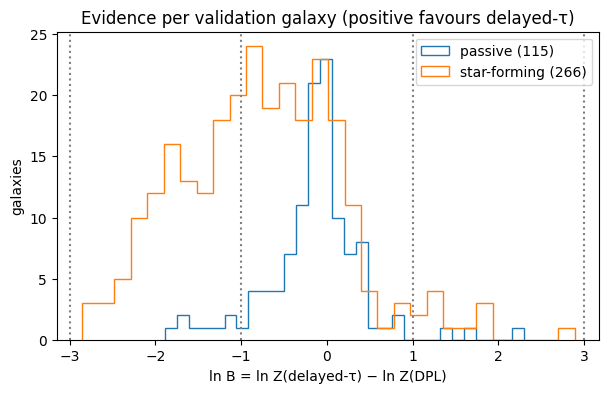

ln B uncertainty: median 0.16 over 381 galaxies; 22% of them have |ln B| below it


In [12]:
if compare_models:
    # 1. ln B and its uncertainty per galaxy, where both photometric fits converged
    evidence_columns = []          # ln Z of each model, then their errors (columns of REFERENCE_FILE)
    for suffix in ("log_evidence", "log_evidence_error"):
        for sfh_model in COMPARED_MODELS:
            evidence_columns.append(f"{sm.PHOTOMETRIC_PREFIXES[sfh_model]}{suffix}")
    evidence_tables = []
    for half in photometric_halves:
        half_galaxies = reference[reference["split"] == half].reset_index(drop=True)
        both_converged = (converged_fits(half_galaxies, sm.PHOTOMETRIC_PREFIXES["delayed"])
                          & converged_fits(half_galaxies, sm.PHOTOMETRIC_PREFIXES["dblplaw"]))
        galaxies = half_galaxies[both_converged].reset_index(drop=True)
        table = pd.DataFrame({"specobjid": galaxies["specobjid"], "half": half,
                              "galaxy_type": spectral_galaxy_types(galaxies)})
        # Why reindex: a column the reference set lacks (no DPL fits read yet, or fits without a stored ln Z
        # error) becomes NaN instead of a KeyError
        log_evidence_delayed, log_evidence_dblplaw, error_delayed, error_dblplaw = (
            galaxies.reindex(columns=evidence_columns).to_numpy(dtype=float).T)
        table["log_bayes"] = ev.log_bayes_factor(log_evidence_delayed, log_evidence_dblplaw)
        table["log_bayes_error"] = ev.log_bayes_factor_error(error_delayed, error_dblplaw)
        evidence_tables.append(table)
    evidence = pd.concat(evidence_tables, ignore_index=True)

    # 2. The distribution of ln B and the share of each category, overall and by galaxy type
    distribution_rows = []
    category_tables = []
    for half in photometric_halves:
        in_half = evidence["half"] == half
        groups = {"all": in_half, "passive": in_half & (evidence["galaxy_type"] == "passive"),
                  "star-forming": in_half & (evidence["galaxy_type"] == "star-forming")}
        for group, in_group in groups.items():
            log_bayes = evidence.loc[in_group, "log_bayes"].to_numpy(dtype=float)
            finite = log_bayes[np.isfinite(log_bayes)]
            percentiles = np.full(3, np.nan)
            if len(finite) > 0:
                percentiles = np.percentile(finite, [16, 50, 84])
            distribution_rows.append({"half": half, "group": group, "n_galaxies": len(finite),
                                      "ln_B_p16": percentiles[0], "ln_B_median": percentiles[1],
                                      "ln_B_p84": percentiles[2]})
            category_tables.append(ev.evidence_category_fractions(log_bayes).assign(half=half, group=group))
    distribution = pd.DataFrame(distribution_rows)
    categories = pd.concat(category_tables, ignore_index=True)
    comparison_tables.append(distribution.assign(section="evidence_distribution"))
    comparison_tables.append(categories.assign(section="evidence_categories"))
    print("ln B = ln Z(delayed-tau) - ln Z(DPL) per galaxy (positive favours delayed-tau)")
    display(distribution.round(2))
    display(categories.set_index(["half", "group", "favoured_model", "strength"])["fraction"]
            .unstack(["favoured_model", "strength"]).round(3))

    figure, axis = plt.subplots(figsize=(7, 4))
    validation_evidence = evidence[evidence["half"] == "validation"]
    for group in ("passive", "star-forming"):
        values = validation_evidence.loc[validation_evidence["galaxy_type"] == group, "log_bayes"].dropna()
        axis.hist(values, bins=30, histtype="step", label=f"{group} ({len(values)})")
    for edge in (-ev.STRONG_LOG_BAYES, -ev.INCONCLUSIVE_LOG_BAYES, ev.INCONCLUSIVE_LOG_BAYES,
                 ev.STRONG_LOG_BAYES):
        axis.axvline(edge, color="grey", ls=":")
    axis.set(xlabel="ln B = ln Z(delayed-τ) − ln Z(DPL)", ylabel="galaxies",
             title="Evidence per validation galaxy (positive favours delayed-τ)")
    axis.legend()
    plt.show()

    # 3. The evidence uncertainty: stored per fit when MultiNest gave it, otherwise its scale sqrt(H / n_live)
    with_error = evidence["log_bayes_error"].notna()
    if with_error.any():
        below_error = (evidence.loc[with_error, "log_bayes"].abs()
                       < evidence.loc[with_error, "log_bayes_error"])
        print(f"ln B uncertainty: median {evidence.loc[with_error, 'log_bayes_error'].median():.2f} over "
              f"{int(with_error.sum())} galaxies; {below_error.mean():.0%} of them have |ln B| below it")
    else:
        print(f"No stored evidence uncertainty in {REFERENCE_FILE}. "
              f"Its scale for n_live = {sm.N_LIVE_POINTS}:")
        for information in (5.0, 10.0, 20.0):
            log_evidence_error = ev.nested_sampling_log_evidence_error(information, sm.N_LIVE_POINTS)
            log_bayes_error = ev.log_bayes_factor_error(log_evidence_error, log_evidence_error)
            print(f"  H = {information:.0f} nats: sigma(ln Z) = {log_evidence_error:.2f}, "
                  f"sigma(ln B) = {log_bayes_error:.2f}")

In [13]:
if compare_models:
    if not os.path.exists(CROSS_FITS_FILE):
        print(f"No {CROSS_FITS_FILE} yet: run notebook 2 (section 6c) after the cross-fits. "
              "True-model recovery skipped")
    else:
        # 1. The mocks whose own fit and cross-fit both converged (notebook 2 checked that every fit
        # is current)
        cross_fits = pd.read_csv(CROSS_FITS_FILE)
        both_converged = (converged_fits(cross_fits, sm.PHOTOMETRIC_PREFIXES["delayed"])
                          & converged_fits(cross_fits, sm.PHOTOMETRIC_PREFIXES["dblplaw"]))
        # ev.true_model_recovery reads log_evidence_<model>; the CSV names them <prefix>log_evidence
        evidence_columns = {}
        for sfh_model, prefix in sm.PHOTOMETRIC_PREFIXES.items():
            evidence_columns[f"{prefix}log_evidence"] = f"log_evidence_{sfh_model}"
        converged_cross_fits = cross_fits[both_converged].rename(columns=evidence_columns)
        print(f"Cross-fitted mocks: {len(cross_fits)} in {CROSS_FITS_FILE}, {int(both_converged.sum())} "
              f"with both fits converged; the other {len(cross_fits) - int(both_converged.sum())} "
              "are left out")

        # 2. How often ln B prefers the true model
        recovery = ev.true_model_recovery(converged_cross_fits)
        comparison_tables.append(recovery.assign(section="true_model_recovery"))
        print("How often ln B prefers the true model (fractions of the mocks of each true model)")
        display(recovery.round(3))

        # 3. The ln B uncertainty of the mocks, from the stored ln Z errors of both fits
        mock_log_bayes_error = ev.log_bayes_factor_error(
            converged_cross_fits[f"{sm.PHOTOMETRIC_PREFIXES['delayed']}log_evidence_error"],
            converged_cross_fits[f"{sm.PHOTOMETRIC_PREFIXES['dblplaw']}log_evidence_error"])
        if np.isfinite(mock_log_bayes_error).any():
            print(f"ln B uncertainty of the mocks: median {np.nanmedian(mock_log_bayes_error):.2f} nats over "
                  f"{int(np.isfinite(mock_log_bayes_error).sum())} mocks")
        else:
            print("No stored ln Z uncertainty for the mocks (fits made before MultiNest's error was stored)")

Cross-fitted mocks: 65 in photometric_cross_fits.csv, 65 with both fits converged; the other 0 are left out
How often ln B prefers the true model (fractions of the mocks of each true model)


,truth_model,n_mocks,prefers_truth,strong_for_truth,inconclusive,strong_for_other
0,delayed,33,0.636,0.030,0.606,0.0
1,dblplaw,32,0.719,0.000,0.938,0.0
2,all,65,0.677,0.015,0.769,0.0


ln B uncertainty of the mocks: median 0.13 nats over 65 mocks


### 5.5 Spectral Bayesian evidence

The spectral ln B = `spec_log_evidence` − `spec_dblplaw_log_evidence` for each galaxy whose two spectral fits converged, in the halves of `halves`; positive favours delayed-τ. Both fits see the same spectrum through the same likelihood (calibration polynomial, noise scale and MultiNest settings), so ln B compares the two SFH priors on these data. The spectra carry far more information than 12 colours, so this tests whether they prefer one SFH shape. The categories are those of section 5.4 (`ev.evidence_category_fractions`: below 1 inconclusive, 1–3 positive, above 3 strong), overall and by galaxy type.

**Uncertainty.** The DPL spectral fits store MultiNest's ln Z error (`spec_dblplaw_log_evidence_error`). The delayed-τ spectral fits made before the error was stored have none (`spec_log_evidence_error` is empty), so their ln B error is unknown. ln Z differences between spectral models are expected to dwarf the usual 0.1–0.3 nats.

**Against the photometric ln B.** For the galaxies with both ln B (the halves of `photometric_halves`):
- the share whose two ln B have the same sign (`ev.log_bayes_sign_agreement`), and the share whose two ln B favour the same model, an inconclusive one counting as favouring neither;
- the counts by the model each favours (`ev.favoured_model_crosstab`, rows photometric, columns spectral);
- a scatter plot of the two.

The spectral ln B axis is drawn as sign(ln B) log10(1 + |ln B|), since spectral ln B may reach hundreds of nats.

In [ ]:
SPECTRAL_EVIDENCE_COLUMNS = {"delayed": "spec_log_evidence", "dblplaw": "spec_dblplaw_log_evidence"}
EVIDENCE_ERROR_SUFFIX = "_error"   # spec_log_evidence_error, spec_dblplaw_log_evidence_error


def signed_log(values):
    """sign(x) log10(1 + |x|): a monotone axis for ln B from 0.1 to thousands of nats, either sign."""
    values = np.asarray(values, dtype=float)
    return np.sign(values) * np.log10(1 + np.abs(values))


def log_bayes_summary(table, column, halves_used):
    """Percentiles and evidence categories of one ln B column, per half, overall and by galaxy type.

    Inputs: table: DataFrame with half, galaxy_type and the ln B column [nats]; halves_used: halves, in order.
    Returns: (distribution, categories): distribution has one row per (half, group) with n_galaxies and
    ln_B_p16 / ln_B_median / ln_B_p84 of the finite ln B [nats]; categories stacks
    ev.evidence_category_fractions per (half, group).
    """
    distribution_rows = []
    category_tables = []
    for half in halves_used:
        in_half = table["half"] == half
        groups = {"all": in_half, "passive": in_half & (table["galaxy_type"] == "passive"),
                  "star-forming": in_half & (table["galaxy_type"] == "star-forming")}
        for group, in_group in groups.items():
            log_bayes = table.loc[in_group, column].to_numpy(dtype=float)
            finite = log_bayes[np.isfinite(log_bayes)]
            percentiles = np.full(3, np.nan)
            if len(finite) > 0:
                percentiles = np.percentile(finite, [16, 50, 84])
            distribution_rows.append({"half": half, "group": group, "n_galaxies": len(finite),
                                      "ln_B_p16": percentiles[0], "ln_B_median": percentiles[1],
                                      "ln_B_p84": percentiles[2]})
            category_tables.append(ev.evidence_category_fractions(log_bayes).assign(half=half, group=group))
    return pd.DataFrame(distribution_rows), pd.concat(category_tables, ignore_index=True)


if compare_models:
    # 1. Spectral ln B and its uncertainty per galaxy, where both spectral fits converged
    spectral_evidence_columns = []   # ln Z of each model, then their errors (columns of REFERENCE_FILE)
    for suffix in ("", EVIDENCE_ERROR_SUFFIX):
        for sfh_model in COMPARED_MODELS:
            spectral_evidence_columns.append(f"{SPECTRAL_EVIDENCE_COLUMNS[sfh_model]}{suffix}")
    spectral_evidence_tables = []
    for half in halves:
        half_galaxies = reference[reference["split"] == half].reset_index(drop=True)
        both_converged = spectral_fits(half_galaxies, "delayed") & spectral_fits(half_galaxies, "dblplaw")
        galaxies = half_galaxies[both_converged].reset_index(drop=True)
        table = pd.DataFrame({"specobjid": galaxies["specobjid"], "half": half,
                              "galaxy_type": spectral_galaxy_types(galaxies)})
        # Why reindex: a column the reference set lacks (no DPL spectral fits read yet, or delayed-tau fits
        # without a stored ln Z error) becomes NaN instead of a KeyError
        log_evidence_delayed, log_evidence_dblplaw, error_delayed, error_dblplaw = (
            galaxies.reindex(columns=spectral_evidence_columns).to_numpy(dtype=float).T)
        table["spectral_log_bayes"] = ev.log_bayes_factor(log_evidence_delayed, log_evidence_dblplaw)
        table["spectral_log_bayes_error"] = ev.log_bayes_factor_error(error_delayed, error_dblplaw)
        spectral_evidence_tables.append(table)
    spectral_evidence = pd.concat(spectral_evidence_tables, ignore_index=True)

    if not np.isfinite(spectral_evidence["spectral_log_bayes"].to_numpy(dtype=float)).any():
        print(f"No galaxy with both spectral ln Z in {REFERENCE_FILE} yet: run notebook 2 after the DPL "
              "spectral fits. Spectral evidence skipped")
    else:
        # 2. The distribution of the spectral ln B and the share of each category, overall and by galaxy type
        spectral_distribution, spectral_categories = log_bayes_summary(spectral_evidence,
                                                                       "spectral_log_bayes", halves)
        comparison_tables.append(spectral_distribution.assign(section="spectral_evidence_distribution"))
        comparison_tables.append(spectral_categories.assign(section="spectral_evidence_categories"))
        print("Spectral ln B = ln Z(delayed-tau spectral) - ln Z(DPL spectral) per galaxy "
              "(positive favours delayed-tau)")
        display(spectral_distribution.round(2))
        display(spectral_categories.set_index(["half", "group", "favoured_model", "strength"])["fraction"]
                .unstack(["favoured_model", "strength"]).round(3))

        figure, axis = plt.subplots(figsize=(7, 4))
        validation_spectral = spectral_evidence[spectral_evidence["half"] == "validation"]
        for group in ("passive", "star-forming"):
            values = validation_spectral.loc[validation_spectral["galaxy_type"] == group,
                                             "spectral_log_bayes"].dropna()
            axis.hist(signed_log(values), bins=30, histtype="step", label=f"{group} ({len(values)})")
        for edge in (-ev.STRONG_LOG_BAYES, -ev.INCONCLUSIVE_LOG_BAYES, ev.INCONCLUSIVE_LOG_BAYES,
                     ev.STRONG_LOG_BAYES):
            axis.axvline(signed_log(edge), color="grey", ls=":")
        axis.set(xlabel="sign(ln B) log10(1 + |ln B|), spectral ln B = ln Z(delayed-τ) − ln Z(DPL)",
                 ylabel="galaxies",
                 title="Spectral evidence per validation galaxy (positive favours delayed-τ)")
        axis.legend()
        plt.show()

        # 3. The spectral ln B uncertainty, where both fits stored their MultiNest ln Z error
        with_error = spectral_evidence["spectral_log_bayes_error"].notna()
        if with_error.any():
            errors = spectral_evidence.loc[with_error, "spectral_log_bayes_error"]
            below_error = spectral_evidence.loc[with_error, "spectral_log_bayes"].abs() < errors
            print(f"Spectral ln B uncertainty: median {errors.median():.2f} over {int(with_error.sum())} "
                  f"galaxies; {below_error.mean():.0%} of them have |ln B| below it")
        else:
            print("No spectral ln B uncertainty: no galaxy has both spectral ln Z errors "
                  f"(the older delayed-tau fits store none); the median |spectral ln B| is "
                  f"{spectral_evidence['spectral_log_bayes'].abs().median():.1f} nats")

        # 4. Against the photometric ln B of section 5.4, on the galaxies with both
        both_evidence = evidence.merge(spectral_evidence[["specobjid", "half", "spectral_log_bayes"]],
                                       on=["specobjid", "half"])
        agreement_rows = []
        crosstab_tables = []
        for half in photometric_halves:
            in_half = both_evidence["half"] == half
            groups = {"all": in_half, "passive": in_half & (both_evidence["galaxy_type"] == "passive"),
                      "star-forming": in_half & (both_evidence["galaxy_type"] == "star-forming")}
            for group, in_group in groups.items():
                photometric_log_bayes = both_evidence.loc[in_group, "log_bayes"]
                spectral_log_bayes = both_evidence.loc[in_group, "spectral_log_bayes"]
                sign_agreement = ev.log_bayes_sign_agreement(photometric_log_bayes, spectral_log_bayes)
                agreement_rows.append({"half": half, "group": group, **sign_agreement})
                crosstab = ev.favoured_model_crosstab(photometric_log_bayes, spectral_log_bayes)
                crosstab_rows = crosstab.stack().rename("n_galaxies").reset_index()
                crosstab_rows = crosstab_rows.rename(columns={"first": "photometric_favours",
                                                              "second": "spectral_favours"})
                crosstab_tables.append(crosstab_rows.assign(half=half, group=group))
                if group == "all":
                    print(f"Galaxies by the model each ln B favours ({half} half; rows photometric, "
                          "columns spectral)")
                    display(crosstab.rename_axis(index="photometric", columns="spectral"))
        evidence_agreement = pd.DataFrame(agreement_rows)
        comparison_tables.append(evidence_agreement.assign(section="evidence_agreement"))
        comparison_tables.append(pd.concat(crosstab_tables, ignore_index=True)
                                 .assign(section="evidence_favoured_models"))
        print("Photometric against spectral ln B: share with the same sign and share favouring the "
              "same model")
        display(evidence_agreement.round(3))

        validation_both = both_evidence[both_evidence["half"] == "validation"]
        if len(validation_both) > 0:
            figure, axis = plt.subplots(figsize=(6, 5))
            for group in ("passive", "star-forming"):
                in_group = validation_both["galaxy_type"] == group
                axis.scatter(validation_both.loc[in_group, "log_bayes"],
                             signed_log(validation_both.loc[in_group, "spectral_log_bayes"]), s=6,
                             label=f"{group} ({int(in_group.sum())})")
            axis.axhline(0, color="grey", lw=1)
            axis.axvline(0, color="grey", lw=1)
            axis.set(xlabel="photometric ln B [nats]", ylabel="sign(ln B) log10(1 + |ln B|), spectral",
                     title="Evidence per validation galaxy (positive favours delayed-τ)")
            axis.legend()
            plt.show()

In [14]:
if compare_models:
    pd.concat(comparison_tables, ignore_index=True).to_csv(COMPARISON_FILE, index=False)
    print(f"wrote {COMPARISON_FILE}")

wrote ml_model_comparison.csv
